<h1 style="text-align: center;">MNIST 数据集和多分类任务</h1>

<p style="text-align: center;">2026-10-31</p>

课程代码均在如下 GitHub 仓库开源：<https://github.com/GHe0000/xmu_machine_learning>

项目自动生成网页地址：<https://ghe0000.github.io/xmu_machine_learning>

## 目录

  - [作业要求](#作业要求)
  - [背景补充](#背景补充)
    - [Softmax Regression](#softmax-regression)
    - [SVM](#svm)
    - [XGBoost](#xgboost)
    - [正交实验](#正交实验)
  - [数据集准备和划分](#数据集准备和划分)
  - [Softmax Regression](#softmax-regression)
    - [Pipline 设置](#pipline-设置)
    - [参数扫描](#参数扫描)
      - [最大迭代次数](#最大迭代次数)
      - [容差](#容差)
      - [正则化强度](#正则化强度)
    - [模型评估](#模型评估)
  - [SVM](#svm)
    - [Pipline 设置](#pipline-设置)
    - [参数扫描](#参数扫描)
      - [容差](#容差)
      - [正则化强度与核函数参数](#正则化强度与核函数参数)
    - [模型评估](#模型评估)
  - [XGBoost](#xgboost)
    - [Pipline 设置](#pipline-设置)
    - [参数扫描](#参数扫描)
      - [训练相关参数](#训练相关参数)
    - [模型相关参数](#模型相关参数)
    - [模型评估](#模型评估)
  - [模型对比](#模型对比)
  - [结论](#结论)
  - [参考资料及 AI 使用说明](#参考资料及-ai-使用说明)
  - [致谢](#致谢)
  - [附一：问题](#附一问题)
  - [附二：学习心得](#附二学习心得)

## 作业要求

比较 Softmax regression, SVM 和 xgboost 三种算法在 MNIST 数据集上的性能。数据在作业附件“mnist.csv"中，包含 1 万个样本。请注意机器学习的完整流程。

## 背景补充

### Softmax Regression

Softmax Regression 是 Logistic Regression 在多分类问题上的推广. 对于具有 $K$ 个类别的分类问题，每个类别对应一组权重和偏置

$$
z_{ik}=\boldsymbol{w}_k^T\boldsymbol{x}_i+b_k
$$

其中 $z_{ik}$ 表示第 $i$ 个样本对于第 $k$ 个类别的得分.

Softmax 函数将得分映射为概率

$$
p_{ik}=\frac{\exp(z_{ik})}{\sum_{j=0}^{K-1}\exp(z_{ij})}
$$

满足

$$
\sum_{k=0}^{K-1}p_{ik}=1
$$

因此模型的预测结果为

$$
\hat y_i=\operatorname*{arg\,max}_{k}p_{ik}
$$

对于多分类问题，使用 Cross-Entropy 作为损失函数

$$
L=-\frac1N\sum_{i=1}^N\sum_{k=0}^{K-1}\mathbb I(y_i=k)\log p_{ik}
$$

也可以写为

$$
L=-\frac1N\sum_{i=1}^N\log p_{i,y_i}
$$

引入 L2 正则化后，优化目标为

$$
J(W,b)=L+\frac{\lambda}{2}\sum_{k=0}^{K-1}\|\boldsymbol{w}_k\|^2
$$

在 `sklearn` 中，使用 `LogisticRegression` 实现 Softmax Regression，使用参数 $C$ 控制正则化强度. $C$ 与正则化强度成反比，$C$ 越大，正则化越弱.



### SVM

SVM 通过最大化分类间隔构造分类边界. 对于二分类软间隔 SVM，其优化目标为

$$
\min_{\boldsymbol w,b,\boldsymbol\xi}
\frac12\|\boldsymbol w\|^2+C\sum_{i=1}^N\xi_i
$$

满足约束条件

$$
y_i(\boldsymbol w^T\boldsymbol x_i+b)\geq1-\xi_i,\qquad \xi_i\geq0
$$

其中 $C$ 控制间隔与分类误差之间的权衡.

为了引入非线性，我们使用 RBF 核函数

$$
K(\boldsymbol x_i,\boldsymbol x_j)
=\exp\left(-\gamma\|\boldsymbol x_i-\boldsymbol x_j\|^2\right)
$$

其中 $\gamma$ 控制核函数的空间尺度. 较小的 $\gamma$ 对应较宽的核函数，较大的 $\gamma$ 对应较窄的核函数.

`sklearn` 中的 `SVC` 内部采用 One-vs-One 方法，训练

$$
\frac{K(K-1)}2=45
$$

个二分类器，组合得到最终预测结果.

### XGBoost

XGBoost 是一种基于树的集成学习方法. 与 Softmax Regression 和 SVM 不同，XGBoost 通过多棵决策树逐步拟合损失函数的梯度信息.

其模型可以写为

$$
F_M(\boldsymbol{x})=\sum_{t=1}^{M}\eta f_t(\boldsymbol{x})
$$

其中 $f_t$ 表示第 $t$ 轮加入的树模型，$M$ 为 Boosting 轮数，$\eta$ 为学习率.

XGBoost 采用带有正则化项的优化目标

$$
J=\sum_{i=1}^{N}l(y_i,\hat y_i)+\sum_{t=1}^{M}\Omega(f_t)
$$

对于树模型，正则化项可以表示为

$$
\Omega(f)=\gamma T+\frac{\lambda}{2}\sum_{j=1}^{T}w_j^2
$$

其中 $T$ 为叶节点数量，$w_j$ 为叶节点权重，$\gamma$ 和 $\lambda$ 分别控制树结构复杂度及叶节点权重的正则化.

我们使用 `XGBClassifier`，并设置 `objective="multi:softprob"`，输出 $10$ 个类别的预测概率.

与前面两种模型不同，决策树只关心特征值的大小顺序，以及能否通过某个阈值将样本分开，而不关心特征值的绝对尺度，因此通常不需要对像素值进行标准化.

### 正交实验

正交实验是一种研究多个因素对实验结果影响的统计实验设计方法. 其核心思想是通过合理安排不同因素及其水平的组合，使得在较少实验次数下，仍然能够均衡地考察各因素对实验结果的影响.

在实际问题中，一个系统的性能往往同时受到多个因素的影响. 如果对每个因素的所有水平组合进行穷举实验，需要进行大量实验，计算成本较高. 正交实验通过选取具有正交性的实验组合，减少实验次数，同时保留对各因素主要影响的分析能力.

正交实验主要涉及以下概念：

- 因素：影响实验结果的变量.
- 水平：因素所设置的不同取值.
- 正交表：按照均衡性和正交性原则构造的实验组合表.

正交表的构造在数学上有对应的方法，这里不再介绍，具体而言：

1. 均衡性：各因素的不同水平在实验中出现的次数相同.
2. 正交性：任意两个因素的水平组合均衡出现.

完成实验后，可以通过极差分析和方差分析，比较不同因素对实验结果的影响程度，从而确定主要影响因素.

正交实验主要用于多因素实验的初步筛选和敏感性分析. 它能够有效减少实验次数，反映最主要的影响因素. 因此，通常先利用正交实验筛选主要因素，再对敏感因素进行进一步扫描和优化.

## 数据集准备和划分

导入需要的库，并对 Jupyter Notebook 进行一定设置.

In [1]:
import numpy as np # 数值计算库
import numba as nb # 引入 jit 来加速函数（如果需要）
import sympy as sym # 符号计算库
import matplotlib as mpl
import matplotlib.pyplot as plt # 图像绘制
from matplotlib.backends.backend_agg import FigureCanvasAgg # 设置图像后端用
import ipywidgets as ipw # 交互控件
from IPython.display import display, Math, Latex # 打印数学公式

import os
import time
import tracemalloc
import matplotlib.text as mtext

import pandas as pd

from io import BytesIO
import matplotlib.animation as animation # 创建动画
from IPython.display import HTML # 动画嵌入
import scipy

from joblib import parallel_backend
from threadpoolctl import threadpool_limits

from sklearn.datasets import make_moons, make_blobs, make_circles, make_classification

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# 模型
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier

# 使用 mathjax 来在 jupyter notebook 显示数学公式
sym.init_printing(use_latex='mathjax')

# 设置 matplotlib 绘制的图像嵌入到 jupyter notebook 的方式
%matplotlib widget

# 一个工具函数，可以让静态图片不经过 widget 直接嵌入 Jupyter notebook
# 这样图片可以直接存到 nb 文件里，而不是需要运行才能显示（类似 inline）
def display_inline(fig):
    try:
        try:
            fig.canvas.draw()
            fig.canvas.flush_events()
        except Exception:
            pass
        fig.set_canvas(FigureCanvasAgg(fig))
        try:
            if hasattr(mtext, "_get_text_metrics_with_cache_impl"):
                mtext._get_text_metrics_with_cache_impl.cache_clear()
        except Exception:
            pass
        try:
            fig.draw_without_rendering()
        except Exception:
            pass
        fig.tight_layout()
        fig.canvas.draw()
        display(fig)
    finally:
        plt.close(fig)  # 释放 fig，减小资源消耗

# 一个工具函数，用于在 Jupyter 中快速实现公式和字符串混合输出
def display_math(*args):
    parts = []
    for a in args:
        if isinstance(a, str):
            parts.append(a)
        else:
            parts.append(sym.latex(a))
    display(Math("".join(parts)))

# 设置 matplotlib 使用的字体，避免出现中文问题
plt.rcParams.update({
    # 字体
    "font.family": ["SimSun", "Times New Roman"],
    "font.size": 14,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    # 字号
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.titlesize": 14,
})

# 设置种子，保证可重复性
rng = np.random.default_rng(3407)
SEED = 3407
N_JOBS = 16

MNIST 数据集包含数字 $0$ 到 $9$ 共 $10$ 个类别. 每个样本为一张 $28\times28$ 的灰度图像，像素值处于 $[0,255]$ 之间.

将图像展开为一维向量，得到

$$
\boldsymbol{x}_i\in\mathbb{R}^{784},\qquad y_i\in\{0,1,\dots,9\}
$$

读取给定的 `mnist.csv`，得到 $10000$ 个样本，我们将数据集按 $8:2$ 划分为 Train 和 Test. 使用分层抽样 `stratify=y`，保持各类别在不同数据集中的比例基本一致. 后续在 Train 内部使用五折交叉验证进行参数优化，不再单独划分固定的 Val.

In [2]:
df = pd.read_csv("mnist.csv")
X = df.drop(columns="label").to_numpy(dtype=np.float32)
y = df["label"].to_numpy(dtype=np.int64)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"All:   X={X.shape}, y={y.shape}")
print(f"Train: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape}, y={y_test.shape}")
print(f"Pixel range: [{X.min():.0f}, {X.max():.0f}]")


All:   X=(10000, 784), y=(10000,)
Train: X=(8000, 784), y=(8000,)
Test:  X=(2000, 784), y=(2000,)
Pixel range: [0, 255]



首先对 MNIST 数据进行可视化，分别选取数字 $0$ 到 $9$ 的一个样本，将长度为 $784$ 的向量重新转换为 $28\times28$ 的矩阵，并展示对应的灰度图像.


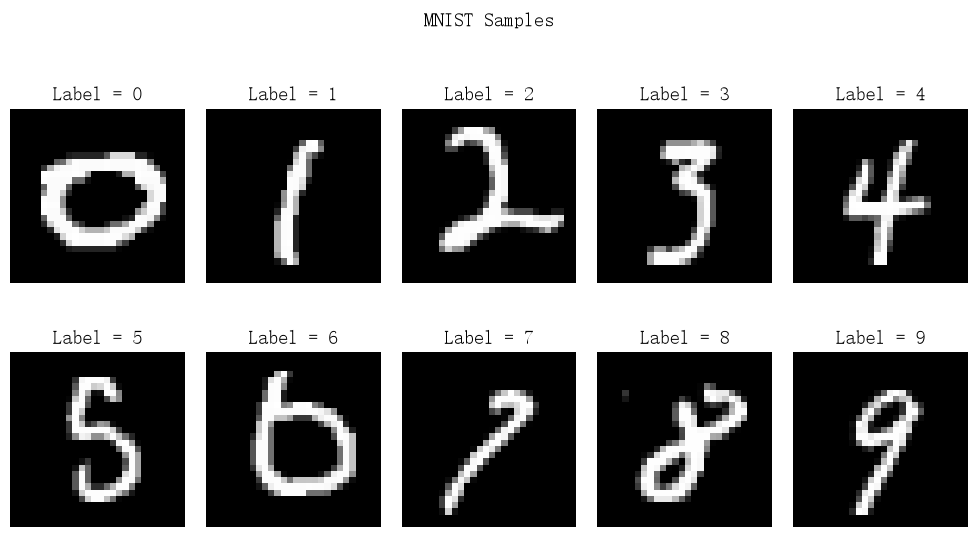

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 6))
for digit, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y_train == digit)[0]
    image = X_train[idx].reshape(28, 28)
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Label = {digit}")
    ax.axis("off")
fig.suptitle("MNIST Samples")
display_inline(fig)

进一步，我们统计不同类别的数量和占比.

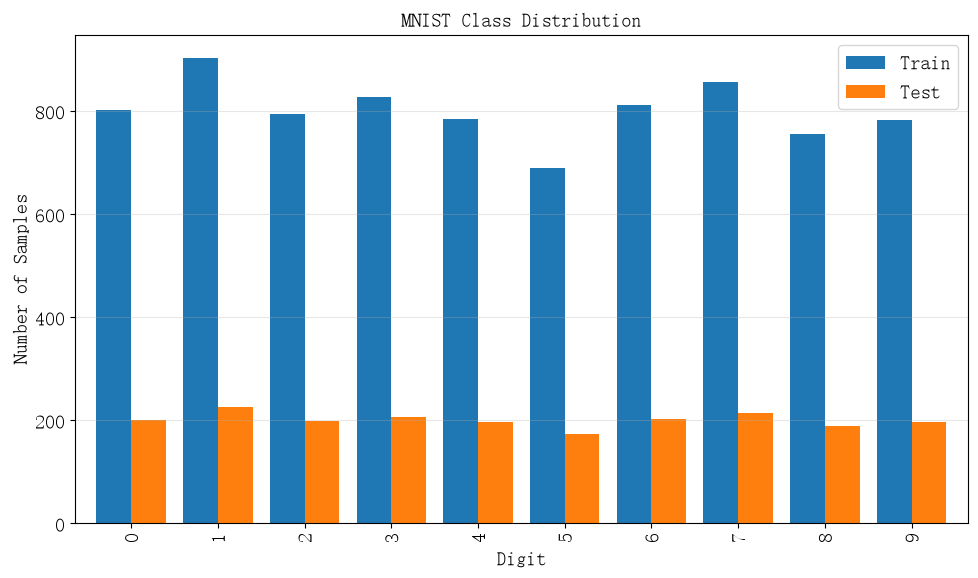

In [4]:

class_counts = pd.DataFrame({
    "Train": np.bincount(y_train, minlength=10),
    "Test": np.bincount(y_test, minlength=10)
}, index=np.arange(10))

fig, ax = plt.subplots(figsize=(10, 6))
class_counts.plot(kind="bar", ax=ax, width=0.8)
ax.set_xlabel("Digit")
ax.set_ylabel("Number of Samples")
ax.set_title("MNIST Class Distribution")
ax.grid(axis="y", alpha=0.3)
ax.legend()
display_inline(fig)

可见，大体而言，各个类别之间的数据数量是接近的，不会出现某一个类别特别多或者特别少的情况. 因此，我们后面可以直接使用 Acc 作为模型的评判指标.

## Softmax Regression

### Pipline 设置

Softmax Regression 我们使用 `sklearn` 中的 `LogisticRegression` 实现. 其中需要指定正则化强度 $C$，训练轮数和允差.

由于原始像素值处于 $[0,255]$，我们首先使用 `MinMaxScaler` 将特征缩放到 $[0,1]$，随后使用 `LogisticRegression` 进行分类.

使用 `Pipeline` 将数据处理与模型训练整合，确保每一折交叉验证仅使用当前训练折的数据拟合缩放参数，从而避免数据泄漏.

初始模型参数设置为

$$
\begin{aligned}
C=1,\quad \text{max\_iter}=400,\quad\text{tol}=10^{-3}
\end{aligned}
$$

In [5]:
softmax_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("softmax", LogisticRegression(
        C=1.0, max_iter=400, tol=1e-3,
        solver="lbfgs", random_state=SEED
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### 参数扫描

#### 最大迭代次数

首先考虑优化算法的最大迭代次数 `max_iter` 对模型的影响.

固定正则化参数和收敛容差，设置不同的迭代轮数，使用五折交叉验证分别计算平均 Train Accuracy 和 CV Accuracy

In [6]:
max_iter_values = [100, 200, 400, 800]

iter_search = GridSearchCV(
    softmax_pipeline,
    param_grid={"softmax__max_iter": max_iter_values},
    scoring="accuracy", cv=cv, n_jobs=N_JOBS,
    refit=True, return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    iter_search.fit(X_train, y_train)

print(f"Time = {time.time() - t_start:.2f} s")
print(f"Best max_iter = {iter_search.best_params_['softmax__max_iter']}")
print(f"Best CV Accuracy = {iter_search.best_score_:.6f}")

Time = 7.30 s
Best max_iter = 100
Best CV Accuracy = 0.905000


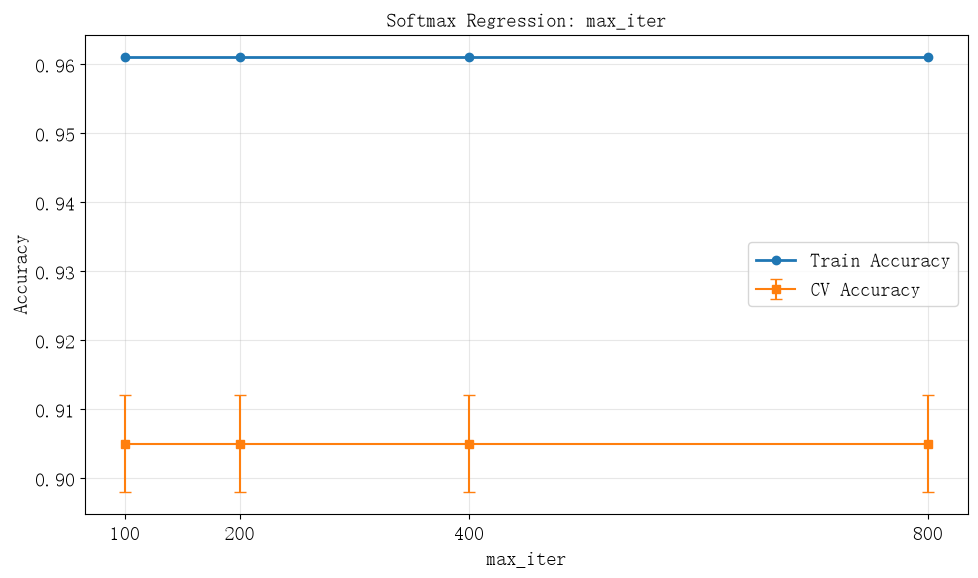

In [7]:
iter_results = pd.DataFrame(iter_search.cv_results_)
iter_results = iter_results.sort_values("param_softmax__max_iter")
x = iter_results["param_softmax__max_iter"].to_numpy(dtype=int)
train_acc = iter_results["mean_train_score"].to_numpy()
cv_acc = iter_results["mean_test_score"].to_numpy()
cv_std = iter_results["std_test_score"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, train_acc, "o-", linewidth=2, label="Train Accuracy")
ax.errorbar(x, cv_acc, yerr=cv_std, fmt="s-", capsize=4, label="CV Accuracy")
ax.set(xlabel="max_iter", ylabel="Accuracy",
       title="Softmax Regression: max_iter")
ax.set_xticks(x)
ax.grid(True, alpha=0.3)
ax.legend()
display_inline(fig)

图中误差棒表示 5 轮 CV Acc 的标准差. 

可以看见，迭代轮数在 $100$ 之后都没有变化，收敛很快. 考虑到更小的容差可能需要更大的训练轮数，后续我们选取 400 作为我们的迭代轮数.

In [8]:
softmax_pipeline.set_params(softmax__max_iter=400);

#### 容差

接下来扫描收敛容差 `tol`. 为了独立分析其影响，固定

$$
C=1,\qquad \mathrm{max\_iter}=400
$$

`tol` 控制优化算法的收敛判据. 较大的 `tol` 允许算法较早终止，可能减少计算时间，但也可能使模型尚未充分收敛. 较小的 `tol` 对收敛要求更加严格，但不一定能够提高分类准确率.

In [9]:
tol_values = [1e-2, 3e-3, 1e-3, 3e-4, 1e-4]

tol_search = GridSearchCV(
    softmax_pipeline,
    param_grid={"softmax__tol": tol_values},
    scoring="accuracy", cv=cv, n_jobs=N_JOBS,
    refit=True, return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    tol_search.fit(X_train, y_train)

print(f"Time = {time.time() - t_start:.2f} s")
print(f"Best tol = {tol_search.best_params_['softmax__tol']:.1e}")
print(f"Best CV Accuracy = {tol_search.best_score_:.6f}")

Time = 9.03 s
Best tol = 3.0e-03
Best CV Accuracy = 0.908125


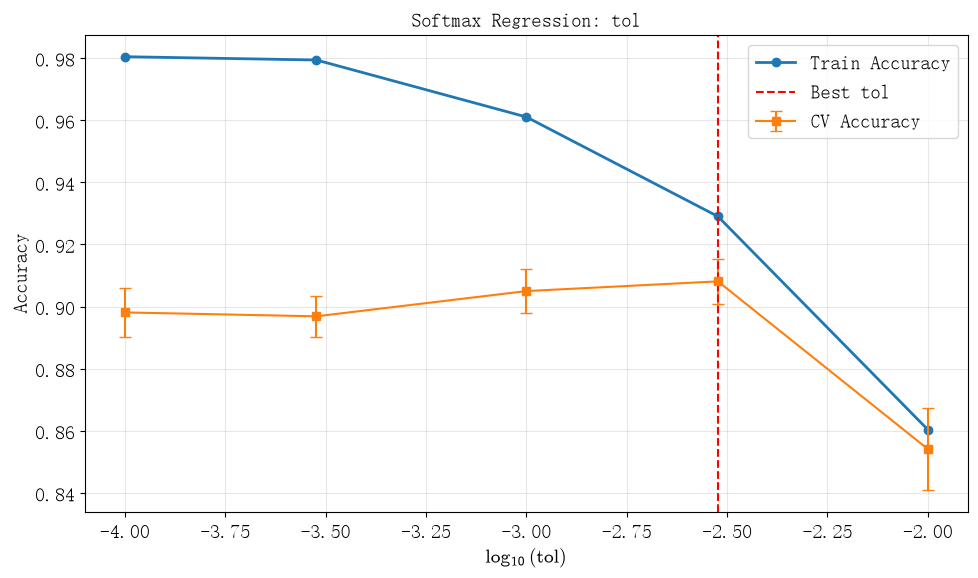

In [10]:
tol_results = pd.DataFrame(tol_search.cv_results_)
tol_results = tol_results.sort_values("param_softmax__tol")

x = np.log10(tol_results["param_softmax__tol"].to_numpy(dtype=float))
train_acc = tol_results["mean_train_score"].to_numpy()
cv_acc = tol_results["mean_test_score"].to_numpy()
cv_std = tol_results["std_test_score"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, train_acc, "o-", linewidth=2, label="Train Accuracy")
ax.errorbar(x, cv_acc, yerr=cv_std, fmt="s-", capsize=4, label="CV Accuracy")
ax.axvline(np.log10(tol_search.best_params_["softmax__tol"]),
           linestyle="--", color="red", label="Best tol")

ax.set(xlabel=r"$\log_{10}(\mathrm{tol})$", ylabel="Accuracy",
       title="Softmax Regression: tol")
ax.grid(True, alpha=0.3)
ax.legend()
display_inline(fig)

可见，随着容差的减小，Train Acc 逐渐增大，CV Acc 先增大后减小，这里我们选取 CV Acc 最好的 tol.

In [11]:
softmax_pipeline.set_params(softmax__tol=3.0e-3);

#### 正则化强度

前面我们扫描的都是模型训练过程中的优化相关的参数. 在确定优化算法参数后，进一步讨论正则化强度对模型泛化能力的影响.

当 $C$ 较小时，正则化较强，模型的权重受到更加严格的约束，可能产生欠拟合. 当 $C$ 较大时，正则化减弱，训练集准确率可能提高，但模型也可能出现过拟合.

正则化参数是模型本身的超参数，这里我们调节更精细些. 我们分两阶段扫描，先大范围粗扫，然后在最优值附近小范围精细扫描.

In [12]:
C_values = np.logspace(-3, 3, 10)

C_search = GridSearchCV(
    softmax_pipeline,
    param_grid={"softmax__C": C_values},
    scoring="accuracy", cv=cv, n_jobs=N_JOBS,
    refit=True, return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    C_search.fit(X_train, y_train)

print(f"Time = {time.time() - t_start:.2f} s")
print(f"Best C = {C_search.best_params_['softmax__C']:.6f}")
print(f"Best CV Accuracy = {C_search.best_score_:.6f}")

Time = 7.57 s
Best C = 10.000000
Best CV Accuracy = 0.908375


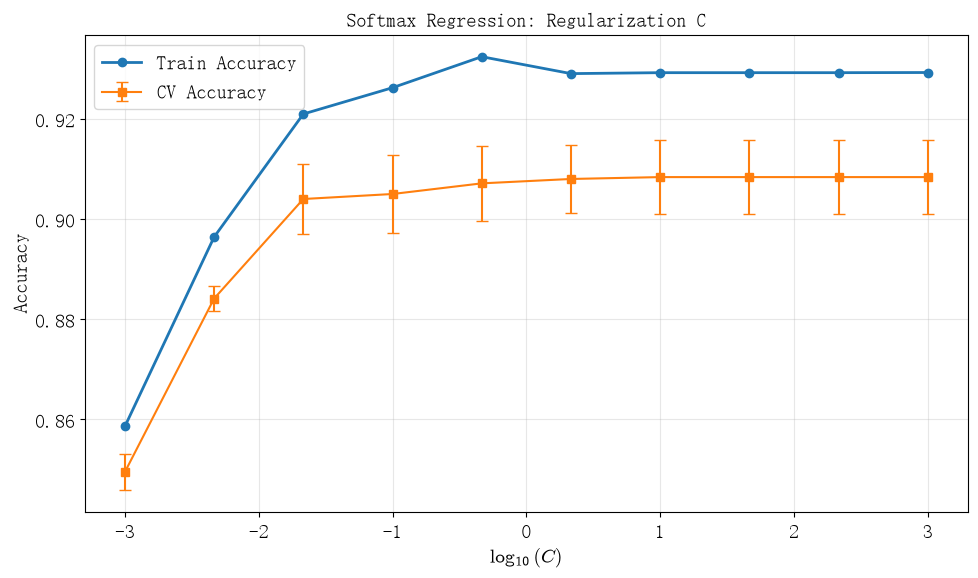

In [13]:
C_results = pd.DataFrame(C_search.cv_results_)
C_results = C_results.sort_values("param_softmax__C")

x = np.log10(C_results["param_softmax__C"].to_numpy(dtype=float))
train_acc = C_results["mean_train_score"].to_numpy()
cv_acc = C_results["mean_test_score"].to_numpy()
cv_std = C_results["std_test_score"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, train_acc, "o-", linewidth=2, label="Train Accuracy")
ax.errorbar(x, cv_acc, yerr=cv_std, fmt="s-", capsize=4, label="CV Accuracy")
ax.set(xlabel=r"$\log_{10}(C)$", ylabel="Accuracy",
       title="Softmax Regression: Regularization C")
ax.grid(True, alpha=0.3)
ax.legend()
display_inline(fig)

可见，当 $C$ 较小时，模型出现明显“欠拟合”（`sklearn` 中 $C$ 是正则化系数的倒数）. 但当 $C$ 增大时，模型没有出现过拟合.

这有两种可能的原因：

- 模型本身是线性模型，可能受到线性判别函数的限制，继续减弱正则化并不能提升模型的表达能力
- Acc 本身对预测概率变化并不敏感（每一次我们都只取最大的概率的 label），因此仍需要结合交叉熵损失判断模型是否发生过拟合

第一个是模型本身的限制（当然我们可以进一步增加 $x^2$ 等高阶项来引入非线性，但对于图像，其增加的项数过多，并不便于计算，因此这里我们不再引入高阶项来引入非线性）. 这里我们不再讨论. 

第二点我们进一步绘制交叉熵：

In [14]:
C_search = GridSearchCV(
    softmax_pipeline,
    param_grid={"softmax__C": C_values},
    scoring={"accuracy": "accuracy", "neg_log_loss": "neg_log_loss"},
    cv=cv, n_jobs=N_JOBS, refit="accuracy",
    return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    C_search.fit(X_train, y_train)

print(f"Time = {time.time() - t_start:.2f} s")
print(f"Best C = {C_search.best_params_['softmax__C']:.6f}")
print(f"Best CV Accuracy = {C_search.best_score_:.6f}")

Time = 8.51 s
Best C = 10.000000
Best CV Accuracy = 0.908375


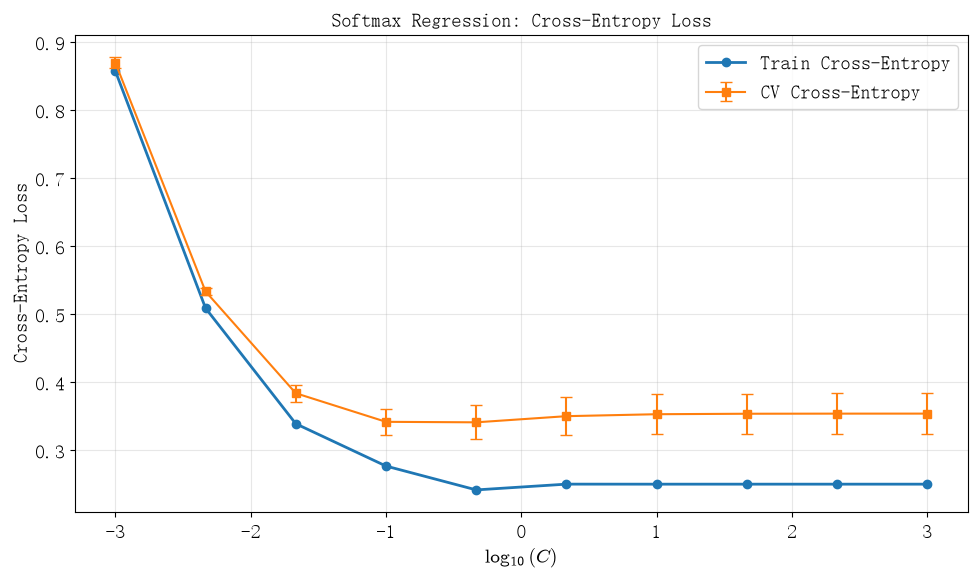

In [15]:
C_results = pd.DataFrame(C_search.cv_results_)
C_results = C_results.sort_values("param_softmax__C")

C_results["mean_train_loss"] = -C_results["mean_train_neg_log_loss"]
C_results["mean_cv_loss"] = -C_results["mean_test_neg_log_loss"]

x = np.log10(C_results["param_softmax__C"].to_numpy(dtype=float))
train_loss = C_results["mean_train_loss"].to_numpy()
cv_loss = C_results["mean_cv_loss"].to_numpy()
cv_std = C_results["std_test_neg_log_loss"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, train_loss, "o-", linewidth=2, label="Train Cross-Entropy")
ax.errorbar(x, cv_loss, yerr=cv_std, fmt="s-", capsize=4, label="CV Cross-Entropy")
ax.set(xlabel=r"$\log_{10}(C)$", ylabel="Cross-Entropy Loss",
       title="Softmax Regression: Cross-Entropy Loss")
ax.grid(True, alpha=0.3)
ax.legend()
display_inline(fig)

从交叉熵曲线来看，CV 交叉熵随着 $C$ 的增大，呈现先降后略微上升的趋势，在 $10^{-1}$ 处取到最值. 但我们注意到，CV Acc 是在 $10$ 之后才稳定的，之前一直是上升的. $10^{-1}$ 不是最优的 Acc 处.

这是因为 Acc 仅关注模型最终预测的类别，而交叉熵考虑模型对真实类别给出的预测概率. 当 $C$ 增大时，L2 正则化减弱，模型可能对预测结果表现出更高的置信度. 这可能改善部分样本的分类结果，同时也可能使模型对错误预测更加自信，导致交叉熵损失增大.

因此，最小化 CE 与最大化 Acc 不一定对应相同的正则化参数.

这里，因为我们最终的目标是预测类别的准确，因此，我们先选取最优的 Acc，再在最优的 Acc 中选取 CE 最小的模型，也就是 $C=10$ 的模型.

In [16]:
softmax_pipeline.set_params(softmax__C=10);

综上，我们得到最优 Softmax Regression 模型. 使用选定的最优参数，在完整 Train 上重新训练 Softmax Regression

In [17]:
t_start = time.time()
with threadpool_limits(limits=N_JOBS):
    softmax_pipeline.fit(X_train, y_train)

### 模型评估

我们将训练得到的最优模型在 Test 上评估分类效果.

分类准确率定义为

$$
\mathrm{Accuracy}=\frac{N_{\mathrm{correct}}}{N_{\mathrm{test}}}
$$

同时绘制混淆矩阵，分析不同手写数字之间的分类错误情况.

In [18]:
y_pred_train = softmax_pipeline.predict(X_train)
y_pred_test = softmax_pipeline.predict(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)

print(f"Train Accuracy = {train_acc:.6f}")
print(f"Test Accuracy = {test_acc:.6f}")

Train Accuracy = 0.930625
Test Accuracy = 0.915000


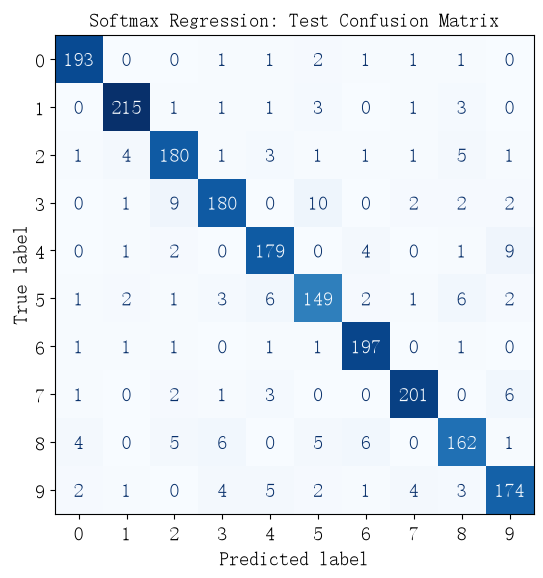

In [19]:
cm = confusion_matrix(y_test, y_pred_test, labels=np.arange(10))

fig, ax = plt.subplots(figsize=(10, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Softmax Regression: Test Confusion Matrix")
display_inline(fig)

对于 Softmax Regression，其 Test Acc 为 0.915, 与 Train Acc 接近，同时混淆矩阵基本在对角线值较高，没有出现明显的某一类错误较多的情况.

## SVM

### Pipline 设置


与 Softmax Regression 类似，我们使用 `Pipeline` 整合归一化和 SVM，防止交叉验证过程中的数据泄漏.

In [20]:
svm_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("svm", SVC(
        C=1.0, gamma="scale", kernel="rbf",
        tol=1e-3, max_iter=-1,
        cache_size=256
    ))
])

这里我们设置使用高斯核，同时设置 `max_iter` 为 -1, 也就是不限制训练轮数.

### 参数扫描

#### 容差

首先扫描 SVM 优化算法的收敛容差 `tol`. 固定

$$
C=1,\qquad \gamma=\mathrm{scale}
$$

`tol` 控制优化过程的停止条件. 较大的 `tol` 可能加快训练，但优化精度较低；较小的 `tol` 要求更加严格的收敛条件.

In [21]:
tol_values = [1e-2, 3e-3, 1e-3, 3e-4, 1e-4]

svm_tol_search = GridSearchCV(
    svm_pipeline,
    param_grid={"svm__tol": tol_values},
    scoring="accuracy", cv=cv, n_jobs=N_JOBS,
    refit=True, return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    svm_tol_search.fit(X_train, y_train)

print(f"Time = {time.time() - t_start:.2f} s")
print(f"Best tol = {svm_tol_search.best_params_['svm__tol']:.1e}")
print(f"Best CV Accuracy = {svm_tol_search.best_score_:.6f}")

Time = 156.72 s
Best tol = 3.0e-03
Best CV Accuracy = 0.955000


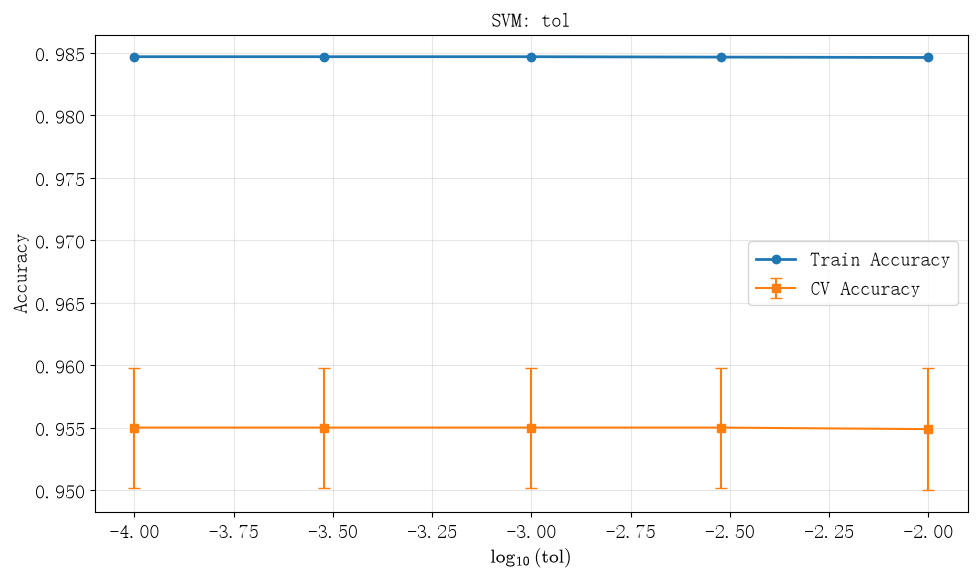

In [22]:
svm_tol_results = pd.DataFrame(svm_tol_search.cv_results_)
svm_tol_results = svm_tol_results.sort_values("param_svm__tol")

x = np.log10(svm_tol_results["param_svm__tol"].to_numpy(dtype=float))
train_acc = svm_tol_results["mean_train_score"].to_numpy()
cv_acc = svm_tol_results["mean_test_score"].to_numpy()
cv_std = svm_tol_results["std_test_score"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, train_acc, "o-", linewidth=2, label="Train Accuracy")
ax.errorbar(x, cv_acc, yerr=cv_std, fmt="s-", capsize=4, label="CV Accuracy")

ax.set(xlabel=r"$\log_{10}(\mathrm{tol})$", ylabel="Accuracy",
       title="SVM: tol")
ax.grid(True, alpha=0.3)
ax.legend()
display_inline(fig)

可见，不同的 `tol` 对最后的 CV Acc 没有明显的变化. 由于较小的 `tol` 会使得训练耗时明显变慢，这里我们选取最大的 `tol` 作为我们后续的 `tol`

In [23]:
svm_pipeline.set_params(svm__tol=0.01);

#### 正则化强度与核函数参数

接下来联合扫描模型参数 $C$ 和 $\gamma$.

不同于前面的训练控制参数，$C$ 和 $\gamma$ 都会影响模型的分类边界，而且两者存在相互作用，因此不应简单地分别进行单参数扫描.

其中 $C$ 控制分类误差的惩罚强度，$\gamma$ 控制 RBF 核函数的空间尺度.

- $C$ 较小：正则化较强，可能欠拟合.
- $C$ 较大：对分类错误的惩罚较强，可能过拟合.
- $\gamma$ 较小：核函数变化较缓慢，分类边界通常较平滑.
- $\gamma$ 较大：核函数更加局域化，分类边界可能更加复杂.

我们使用二维网格搜索，使用五折交叉验证计算每组参数的 Train Accuracy 和 CV Accuracy. 先在一个较大网格搜索，之后在细化.

由于 RBF SVM 在数据量大时计算很慢，扫描更慢，因此，我们抽取出 2000 个样本组成的小数据集，并在小数据集中进行扫描确定超参.

In [24]:
n_search = 2000

X_search, _, y_search, _ = train_test_split(
    X_train, y_train, train_size=n_search,
    stratify=y_train, random_state=3407
)

In [25]:
C_values = np.logspace(-2, 2, 5)
gamma_values = np.logspace(-3, 0, 5)

svm_search = GridSearchCV(
    svm_pipeline,
    param_grid={"svm__C": C_values, "svm__gamma": gamma_values},
    scoring="accuracy", cv=cv, n_jobs=N_JOBS,
    refit=True, return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    svm_search.fit(X_search, y_search)

In [26]:
print(f"Time = {time.time() - t_start:.2f} s")
print(f"Best CV Accuracy = {svm_search.best_score_:.6f}")

Time = 105.89 s
Best CV Accuracy = 0.921500


由于本次同时扫描两个参数，我们使用二维热力图观察 CV Accuracy 关于 $C$ 和 $\gamma$ 的变化.

横坐标为 $\log_{10}C$，纵坐标为 $\log_{10}\gamma$，颜色表示平均 CV Accuracy.

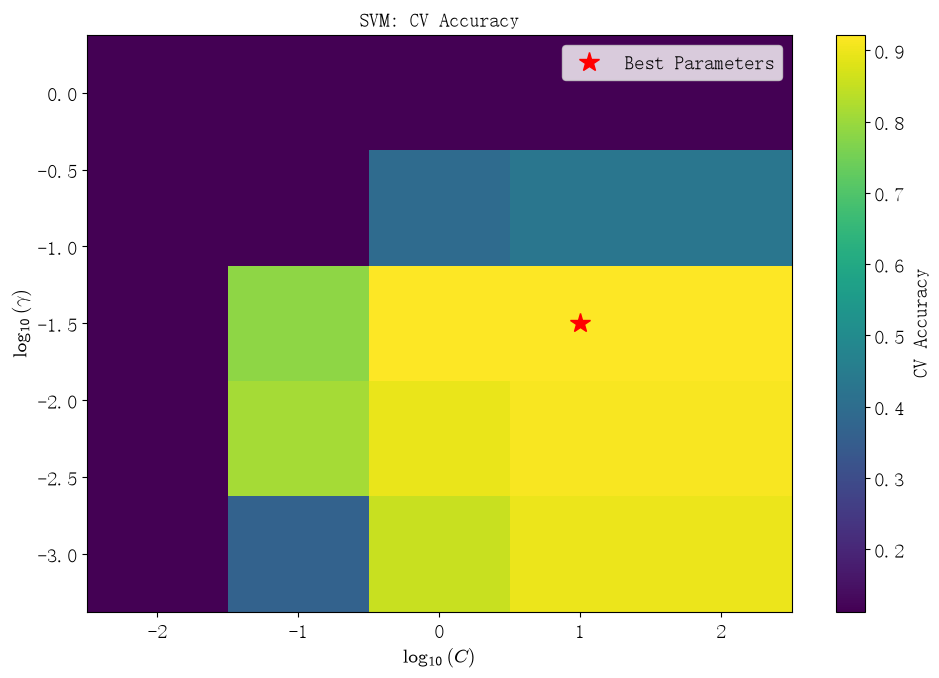

In [27]:
svm_results = pd.DataFrame(svm_search.cv_results_)
svm_results = svm_results.sort_values(["param_svm__C", "param_svm__gamma"])
cv_matrix = svm_results.pivot(
    index="param_svm__gamma",
    columns="param_svm__C",
    values="mean_test_score"
)
cv_matrix = cv_matrix.reindex(index=gamma_values, columns=C_values)

log_C = np.log10(C_values)
log_gamma = np.log10(gamma_values)
Z = cv_matrix.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(10, 7))
pcm = ax.pcolormesh(log_C, log_gamma, Z, shading="nearest", cmap="viridis")
ax.plot(np.log10(svm_search.best_params_["svm__C"]),
        np.log10(svm_search.best_params_["svm__gamma"]),
        "r*", markersize=15, label="Best Parameters")

ax.set(xlabel=r"$\log_{10}(C)$", ylabel=r"$\log_{10}(\gamma)$",
       title="SVM: CV Accuracy")
ax.legend()
fig.colorbar(pcm, ax=ax, label="CV Accuracy")
display_inline(fig)

从第一次扫描的热力图可以观察到，$C$ 和 $\gamma$ 对模型性能具有明显的共同影响. 当 $C$ 较小、$\gamma$ 较大时，CV Acc 较低. 随着 $C$ 增大以及 $\gamma$ 减小，模型的分类准确率显著提高. 这说明过强的正则化或过于局域化的核函数都可能限制模型的泛化性能.

我们进一步在 $(10,0.03)$ 附近扫描：

In [28]:
C_values = np.logspace(-0.5, 1.5, 10)
gamma_values = np.logspace(-1, -2, 10)
svm_search = GridSearchCV(
    svm_pipeline,
    param_grid={"svm__C": C_values, "svm__gamma": gamma_values},
    scoring="accuracy",
    cv=cv, n_jobs=N_JOBS,
    refit="accuracy", return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    svm_search.fit(X_search, y_search)
print(f"Time = {time.time() - t_start:.2f} s")
print(f"Best CV Accuracy = {svm_search.best_score_:.6f}")

Time = 359.41 s
Best CV Accuracy = 0.923500


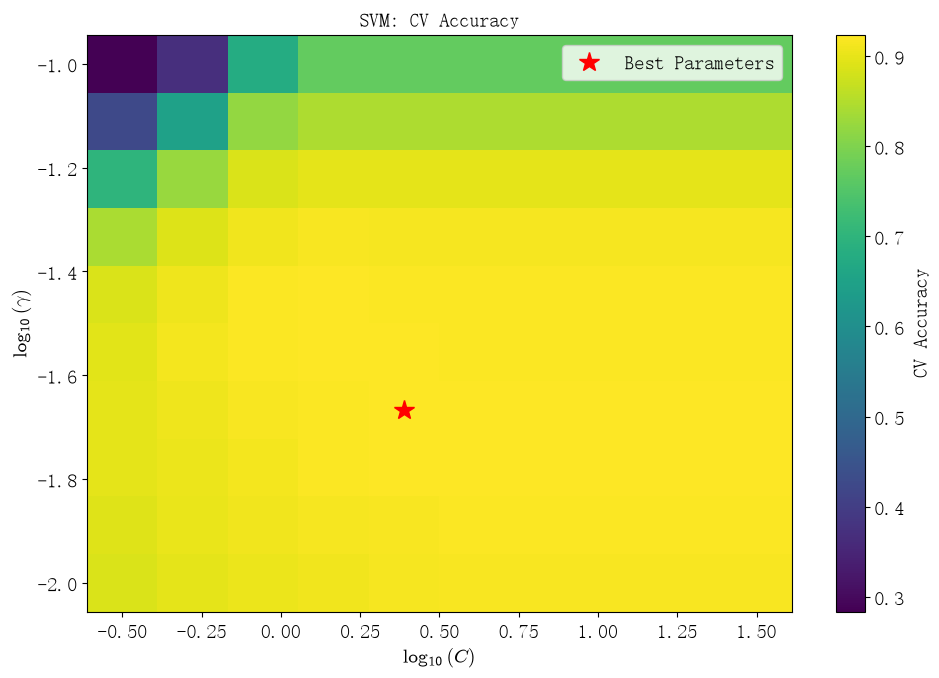

In [29]:
svm_results = pd.DataFrame(svm_search.cv_results_)
svm_results = svm_results.sort_values(["param_svm__C", "param_svm__gamma"])
cv_matrix = svm_results.pivot(
    index="param_svm__gamma",
    columns="param_svm__C",
    values="mean_test_score"
)
cv_matrix = cv_matrix.reindex(index=gamma_values, columns=C_values)

log_C = np.log10(C_values)
log_gamma = np.log10(gamma_values)
Z = cv_matrix.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(10, 7))
pcm = ax.pcolormesh(log_C, log_gamma, Z, shading="nearest", cmap="viridis")
ax.plot(np.log10(svm_search.best_params_["svm__C"]),
        np.log10(svm_search.best_params_["svm__gamma"]),
        "r*", markersize=15, label="Best Parameters")

ax.set(xlabel=r"$\log_{10}(C)$", ylabel=r"$\log_{10}(\gamma)$",
       title="SVM: CV Accuracy")
ax.legend()
fig.colorbar(pcm, ax=ax, label="CV Accuracy")
display_inline(fig)

第二次扫描发现，在一定范围内，CV Accuracy 对 $C$ 和 $\gamma$ 的变化不再十分敏感，形成了较为明显的高准确率平台. 最优参数大约为 $C=2.15$、$\gamma=0.0215$. 这说明模型在该参数区域内具有一定的稳定性，参数的微小变化不会引起分类准确率的显著改变.

因此，我们以此设置 $C$ 和 $\gamma$，并使用全数据集进行完整训练

In [30]:
svm_pipeline.set_params(
    svm__C=svm_search.best_params_["svm__C"],
    svm__gamma=svm_search.best_params_["svm__gamma"]
);
t_start = time.time()
with threadpool_limits(limits=N_JOBS):
    svm_pipeline.fit(X_train, y_train)
print(f"Training Time = {time.time() - t_start:.2f} s")

Training Time = 14.12 s


### 模型评估

使用完整 Train 训练得到的 SVM 模型，分别计算 Train 和 Test 的分类准确率. 并绘制混淆矩阵.

In [31]:
y_pred_train_svm = svm_pipeline.predict(X_train)
y_pred_test_svm = svm_pipeline.predict(X_test)

train_acc_svm = accuracy_score(y_train, y_pred_train_svm)
test_acc_svm = accuracy_score(y_test, y_pred_test_svm)

print(f"Train Accuracy = {train_acc_svm:.6f}")
print(f"Test Accuracy = {test_acc_svm:.6f}")

Train Accuracy = 0.999250
Test Accuracy = 0.968500


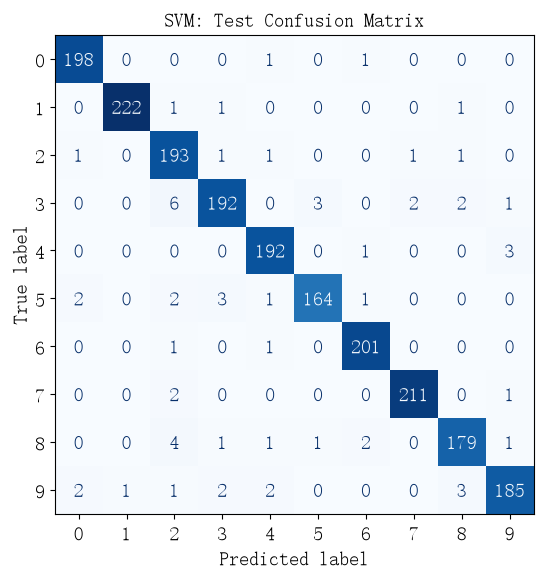

In [32]:
cm_svm = confusion_matrix(y_test, y_pred_test_svm, labels=np.arange(10))

fig, ax = plt.subplots(figsize=(10, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=np.arange(10)
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("SVM: Test Confusion Matrix")
display_inline(fig)

对于 SVM，其 Test Acc 为 0.968. 同时混淆矩阵基本在对角线值较高，没有出现明显的某一类错误较多的情况.

可以发现，相比于 Softmax Regression，SVM 通过核函数引入非线性分类能力，因此能够表达更加复杂的分类关系. 从而实现更优的 Acc.

## XGBoost

### Pipline 设置

我们仍使用 `Pipeline` ，但不再引入 `MinMaxScaler`. 

根据 AI 代码补全的建议，设置 `tree_method="hist"`，使用直方图算法加速决策树的构造（更多是为了加速训练）.

初始模型使用

$$
\begin{aligned}
\mathrm{n\_estimators}&=200\\
\mathrm{learning\_rate}&=0.1\\
\mathrm{max\_depth}&=5\\
\mathrm{min\_child\_weight}&=1\\
\mathrm{subsample}&=0.8\\
\mathrm{colsample\_bytree}&=0.8\\
\mathrm{reg\_lambda}&=1.0\\
\mathrm{reg\_alpha}&=0
\end{aligned}
$$

其中 `n_estimators` 控制训练轮数，`learning_rate` 控制每轮新增模型的更新幅度. `max_depth` 控制每棵树的最大深度，`min_child_weight` 控制子节点的最小二阶统计量，越大树的建立越保守. `subsample` 控制一次训练中随机选取的样本比例 `colsample_bytree` 控制每一颗数使用的特征在所有特征的占比，`reg_lambda` 控制 L2 正则化系数，`reg_alpha` 控制 L1 正则化系数，这里我们只使用 L2, 不使用 L1.

In [50]:
xgb_pipeline = Pipeline([
    ("xgb", XGBClassifier(
        objective="multi:softprob", num_class=10,
        eval_metric="mlogloss", tree_method="hist",
        n_estimators=200, learning_rate=0.1,
        max_depth=5, min_child_weight=1,
        subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, reg_alpha=0,
        random_state=SEED, n_jobs=1
    ))
])

在这些参数中，我们分为下面两类：

训练相关超参：
- `n_estimators` 
- `learning_rate`

模型相关超参：
- `max_depth`
- `min_child_weight`
- `subsample`
- `colsample_bytree`
- `reg_lambda`

前者由于训练轮数和学习率相关，我们使用联合扫描.

剩下多个我们使用联合扫描，确定最优参数.

同时，由于单次训练较慢，我们使用前面划分的子数据集进行参数调优. 确定最优参数后再选取全部参数进行训练.

### 参数扫描

#### 训练相关参数

In [34]:
n_estimators_values = [50, 100, 150, 200]
learning_rate_values = [0.03, 0.05, 0.1, 0.2]

xgb_search_n_lr = GridSearchCV(
    xgb_pipeline,
    param_grid={
        "xgb__n_estimators": n_estimators_values,
        "xgb__learning_rate": learning_rate_values
    },
    scoring="accuracy", cv=cv, n_jobs=N_JOBS,
    refit=True, return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS):
    xgb_search_n_lr.fit(X_search, y_search)

best_n = xgb_search_n_lr.best_params_["xgb__n_estimators"]
best_lr = xgb_search_n_lr.best_params_["xgb__learning_rate"]

print(f"最优 n_estimators: {best_n}")
print(f"最优 learning_rate: {best_lr}")
print(f"最优 CV Accuracy: {xgb_search_n_lr.best_score_:.6f}")
print(f"耗时: {time.time() - t_start:.2f} s")

最优 n_estimators: 200
最优 learning_rate: 0.1
最优 CV Accuracy: 0.907500
耗时: 354.42 s


绘制热力图：

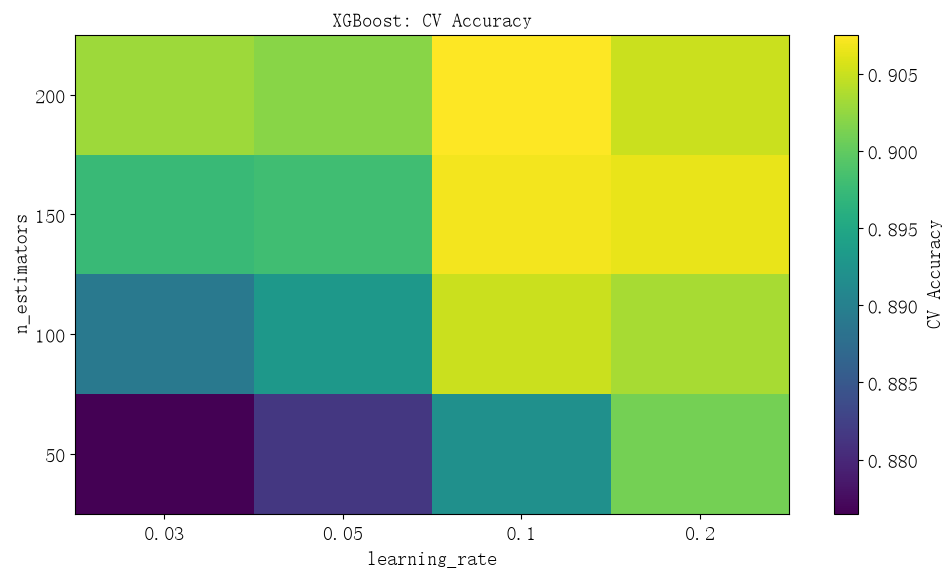

In [35]:
results = pd.DataFrame(xgb_search_n_lr.cv_results_)

heatmap = results.pivot(
    index="param_xgb__n_estimators",
    columns="param_xgb__learning_rate",
    values="mean_test_score"
).sort_index().sort_index(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(heatmap.values, origin="lower", aspect="auto", cmap="viridis")
ax.set_xticks(range(len(heatmap.columns)), labels=heatmap.columns)
ax.set_yticks(range(len(heatmap.index)), labels=heatmap.index)
ax.set_xlabel("learning_rate")
ax.set_ylabel("n_estimators")
ax.set_title("XGBoost: CV Accuracy")
fig.colorbar(im, ax=ax, label="CV Accuracy")
display_inline(fig)

可以发现，在我们的扫描范围内，在 $(0.1,200)$ 附近的 CV Acc 比较好，我们在这附近使用更密的网格扫描：

In [36]:
n_estimators_values = [160, 180, 200, 220, 240]
learning_rate_values = [0.05, 0.1, 0.15]

xgb_search_n_lr = GridSearchCV(
    xgb_pipeline,
    param_grid={
        "xgb__n_estimators": n_estimators_values,
        "xgb__learning_rate": learning_rate_values
    },
    scoring="accuracy", cv=cv, n_jobs=N_JOBS,
    refit=True, return_train_score=True
)

t_start = time.time()
with parallel_backend("threading", n_jobs=N_JOBS):
    xgb_search_n_lr.fit(X_search, y_search)

best_n = xgb_search_n_lr.best_params_["xgb__n_estimators"]
best_lr = xgb_search_n_lr.best_params_["xgb__learning_rate"]

print(f"最优 n_estimators: {best_n}")
print(f"最优 learning_rate: {best_lr}")
print(f"最优 CV Accuracy: {xgb_search_n_lr.best_score_:.6f}")
print(f"耗时: {time.time() - t_start:.2f} s")

最优 n_estimators: 180
最优 learning_rate: 0.1
最优 CV Accuracy: 0.908500
耗时: 421.91 s


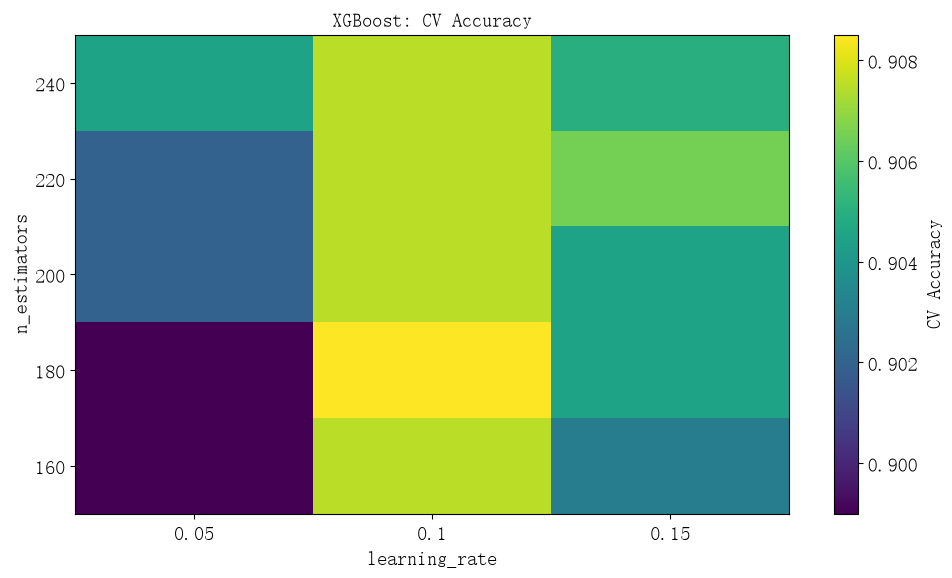

In [37]:
results = pd.DataFrame(xgb_search_n_lr.cv_results_)

heatmap = results.pivot(
    index="param_xgb__n_estimators",
    columns="param_xgb__learning_rate",
    values="mean_test_score"
).sort_index().sort_index(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(heatmap.values, origin="lower", aspect="auto", cmap="viridis")
ax.set_xticks(range(len(heatmap.columns)), labels=heatmap.columns)
ax.set_yticks(range(len(heatmap.index)), labels=heatmap.index)
ax.set_xlabel("learning_rate")
ax.set_ylabel("n_estimators")
ax.set_title("XGBoost: CV Accuracy")
fig.colorbar(im, ax=ax, label="CV Accuracy")
display_inline(fig)

综上，我们确定训练参数为 `n_estimators` 180 `learning_rate` 0.1

In [51]:
xgb_pipeline.set_params(
    xgb__n_estimators=180,
    xgb__learning_rate=0.1
);

### 模型相关参数

这里对 XGBoost 的五个模型相关超参数进行联合扫描，分别为 `max_depth`、`min_child_weight`、`subsample`、`colsample_bytree` 和 `reg_lambda`.

其中，`max_depth` 和 `min_child_weight` 控制决策树的结构复杂度，`subsample` 和 `colsample_bytree` 控制训练样本和特征的采样比例，`reg_lambda` 控制叶节点权重的 L2 正则化强度. 这些参数共同影响模型的拟合能力和泛化性能.

由于计算和扫描很慢，因此这里我们不直接进行联合参数扫描，而是采用两阶段优化策略.

首先使用正交实验分析不同参数对模型性能的影响，确定参数敏感度. 随后重点选择影响最大的几个参数进行进一步扫描和优化.

参数搜索均使用训练集的子集进行，最终确定参数后再使用完整训练集训练模型.

In [49]:
factor_levels = {
    "xgb__max_depth": [3, 5, 7],
    "xgb__min_child_weight": [1, 5, 10],
    "xgb__subsample": [0.6, 0.8, 1.0],
    "xgb__colsample_bytree": [0.6, 0.8, 1.0],
    "xgb__reg_lambda": [0.01, 0.1, 1.0]
}

factor_names = list(factor_levels)
oa_rows = []

for a in range(3):
    for b in range(3):
        for c in range(3):
            indices = [a, b, c, (a + b) % 3, (a + 2 * b) % 3]
            row = {
                name: levels[idx]
                for (name, levels), idx in zip(factor_levels.items(), indices)
            }
            oa_rows.append(row)
oa_design = pd.DataFrame(oa_rows)
print(f"正交实验组数: {len(oa_design)}")

正交实验组数: 27


In [52]:
oa_param_grid = [
    {name: [value] for name, value in row.items()}
    for row in oa_design.to_dict("records")
]

xgb_oa_search = GridSearchCV(
    xgb_pipeline,
    param_grid=oa_param_grid,
    scoring={
        "accuracy": "accuracy",
        "neg_log_loss": "neg_log_loss"
    },
    cv=cv, n_jobs=N_JOBS,
    refit="accuracy", return_train_score=True
)

t_start = time.time()

with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    xgb_oa_search.fit(X_search, y_search)

print(f"Time = {time.time() - t_start:.2f} s")
print(f"Orthogonal Runs = {len(oa_design)}")
print(f"Best Parameters = {xgb_oa_search.best_params_}")
print(f"Best CV Accuracy = {xgb_oa_search.best_score_:.6f}")

Time = 469.26 s
Orthogonal Runs = 27
Best Parameters = {'xgb__colsample_bytree': 0.6, 'xgb__max_depth': 3, 'xgb__min_child_weight': 1, 'xgb__reg_lambda': 0.01, 'xgb__subsample': 0.8}
Best CV Accuracy = 0.909500


正交实验完成后，需要分析不同参数水平对模型性能的影响.

以参数 $A$ 为例，将其取不同水平时的实验结果分别求平均：

$$
\overline{A}_i=
\frac{1}{n_i}
\sum_{j=1}^{n_i}A_{ij}
$$

其中 $A_{ij}$ 表示参数 $A$ 取第 $i$ 个水平时，第 $j$ 组实验的交叉验证准确率.

首先使用极差分析：

$$
R_A=\max_i\overline A_i-\min_i\overline A_i
$$

极差越大，说明参数变化对模型性能的影响越明显.

进一步使用方差分析，计算各因素的主效应平方和：

$$
SS_A=\sum_{i=1}^{3}n_i(\overline A_i-\overline A)^2
$$

其中 $\overline A$ 为所有实验的平均准确率.

定义主效应贡献率：

$$
\eta_A=\frac{SS_A}{SS_{\mathrm{total}}}\times100\%
$$

贡献率越大，说明该参数的主效应能够解释更多的模型性能变化.

分别对 Accuracy 和 Log Loss 进行分析.

In [53]:
xgb_oa_results = pd.DataFrame(xgb_oa_search.cv_results_)

xgb_oa_results["mean_cv_loss"] = (
    -xgb_oa_results["mean_test_neg_log_loss"]
)
xgb_oa_results["mean_train_loss"] = (
    -xgb_oa_results["mean_train_neg_log_loss"]
)

effect_tables = {}
main_effect_best = {}
sensitivity_rows = []

for name in factor_names:
    col = f"param_{name}"
    xgb_oa_results[col] = pd.to_numeric(xgb_oa_results[col])

    effect = xgb_oa_results.groupby(col).agg(
        cv_accuracy=("mean_test_accuracy", "mean"),
        cv_logloss=("mean_cv_loss", "mean"),
        n=("mean_test_accuracy", "size")
    )

    effect_tables[name] = effect

    grand_acc = xgb_oa_results["mean_test_accuracy"].mean()
    acc_delta = effect["cv_accuracy"].max() - effect["cv_accuracy"].min()

    acc_ss = (
        (effect["cv_accuracy"] - grand_acc) ** 2 * effect["n"]
    ).sum()

    acc_total_ss = (
        (xgb_oa_results["mean_test_accuracy"] - grand_acc) ** 2
    ).sum()

    acc_contribution = (
        100 * acc_ss / acc_total_ss if acc_total_ss > 0 else 0
    )

    grand_loss = xgb_oa_results["mean_cv_loss"].mean()
    loss_delta = effect["cv_logloss"].max() - effect["cv_logloss"].min()

    loss_ss = (
        (effect["cv_logloss"] - grand_loss) ** 2 * effect["n"]
    ).sum()

    loss_total_ss = (
        (xgb_oa_results["mean_cv_loss"] - grand_loss) ** 2
    ).sum()

    loss_contribution = (
        100 * loss_ss / loss_total_ss if loss_total_ss > 0 else 0
    )

    best_level = effect.sort_values(
        ["cv_accuracy", "cv_logloss"],
        ascending=[False, True]
    ).index[0]

    best_loss_level = effect["cv_logloss"].idxmin()
    main_effect_best[name] = best_level

    sensitivity_rows.append({
        "Parameter": name.replace("xgb__", ""),
        "Accuracy Range": acc_delta,
        "Accuracy Contribution (%)": acc_contribution,
        "Best Accuracy Level": best_level,
        "LogLoss Range": loss_delta,
        "LogLoss Contribution (%)": loss_contribution,
        "Best LogLoss Level": best_loss_level
    })

xgb_oa_sensitivity = pd.DataFrame(sensitivity_rows).sort_values(
    "Accuracy Contribution (%)", ascending=False
).reset_index(drop=True)

display(xgb_oa_sensitivity.round(6))

,Parameter,Accuracy Range,Accuracy Contribution (%),Best Accuracy Level,LogLoss Range,LogLoss Contribution (%),Best LogLoss Level
0,min_child_weight,0.012500,78.727375,1.00,0.053820,88.135454,1.0
1,subsample,0.003000,5.000933,0.80,0.006811,1.599461,0.8
2,colsample_bytree,0.002833,4.609069,0.60,0.006363,1.359643,0.6
3,reg_lambda,0.001333,1.063631,0.01,0.003356,0.341934,0.1
4,max_depth,0.000500,0.167942,3.00,0.003706,0.463417,7.0


根据前面的参数敏感性分析，我们发现 `min_child_weight`、`subsample` 和 `colsample_bytree` 对模型性能影响较大，因此进一步对这三个参数进行联合扫描.

其余两个参数固定为：

- `max_depth = 3`
- `reg_lambda = 0.01`

采用三维网格搜索.

In [54]:
xgb_pipeline.set_params(
    xgb__max_depth=3,
    xgb__reg_lambda=0.01
)

fine_grid = {
    "xgb__min_child_weight": [0.25, 0.5, 1.0],
    "xgb__subsample": [0.7, 0.8, 0.9],
    "xgb__colsample_bytree": [0.4, 0.5, 0.6]
}

xgb_fine_search = GridSearchCV(
    xgb_pipeline,
    param_grid=fine_grid,
    scoring={
        "accuracy": "accuracy",
        "neg_log_loss": "neg_log_loss"
    },
    cv=cv, n_jobs=N_JOBS,
    refit="accuracy", return_train_score=True
)

t_start = time.time()

with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    xgb_fine_search.fit(X_search, y_search)

xgb_fine_results = pd.DataFrame(xgb_fine_search.cv_results_)

xgb_fine_results["mean_cv_loss"] = (
    -xgb_fine_results["mean_test_neg_log_loss"]
)
xgb_fine_results["mean_train_loss"] = (
    -xgb_fine_results["mean_train_neg_log_loss"]
)

print(f"耗时: {time.time() - t_start:.2f} s")
print(f"最优参数: {xgb_fine_search.best_params_}")
print(f"Best CV Accuracy: {xgb_fine_search.best_score_:.6f}")

耗时: 378.67 s
最优参数: {'xgb__colsample_bytree': 0.5, 'xgb__min_child_weight': 0.25, 'xgb__subsample': 0.8}
Best CV Accuracy: 0.914500


扫描得到的最优参数为：

$$
\begin{aligned}
\mathrm{min\_child\_weight}&=0.25\\
\mathrm{subsample}&=0.8\\
\mathrm{colsample\_bytree}&=0.5
\end{aligned}
$$

其中，`min_child_weight` 的最优值仍然位于扫描范围的下边界，因此进一步向较小值扩展.

In [56]:
xgb_pipeline.set_params(
    xgb__max_depth=3,
    xgb__reg_lambda=0.01
)

fine2_grid = {
    "xgb__min_child_weight": [0.05, 0.1, 0.25, 0.5],
    "xgb__subsample": [0.7, 0.8, 0.9],
    "xgb__colsample_bytree": [0.4, 0.5, 0.6]
}

xgb_fine2_search = GridSearchCV(
    xgb_pipeline,
    param_grid=fine2_grid,
    scoring={
        "accuracy": "accuracy",
        "neg_log_loss": "neg_log_loss"
    },
    cv=cv, n_jobs=N_JOBS,
    refit="accuracy", return_train_score=True
)

t_start = time.time()

with parallel_backend("threading", n_jobs=N_JOBS), threadpool_limits(limits=1):
    xgb_fine2_search.fit(X_search, y_search)

xgb_fine2_results = pd.DataFrame(xgb_fine2_search.cv_results_)

xgb_fine2_results["mean_cv_loss"] = (
    -xgb_fine2_results["mean_test_neg_log_loss"]
)
xgb_fine2_results["mean_train_loss"] = (
    -xgb_fine2_results["mean_train_neg_log_loss"]
)

print(f"Time = {time.time() - t_start:.2f} s")
print(f"Best Parameters = {xgb_fine2_search.best_params_}")
print(f"Best CV Accuracy = {xgb_fine2_search.best_score_:.6f}")

Time = 506.31 s
Best Parameters = {'xgb__colsample_bytree': 0.5, 'xgb__min_child_weight': 0.25, 'xgb__subsample': 0.8}
Best CV Accuracy = 0.914500


In [57]:
final_xgb = xgb_fine2_search.best_estimator_
t_start = time.time()
final_xgb.fit(X_train, y_train)
print(f"Training Time = {time.time() - t_start:.2f} s")

Training Time = 75.35 s


### 模型评估 

In [58]:
y_train_pred = final_xgb.predict(X_train)
y_test_pred = final_xgb.predict(X_test)

# 模型评估
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Best CV Accuracy = {xgb_fine2_search.best_score_:.6f}")
print(f"Full Train Accuracy = {train_acc:.6f}")
print(f"Test Accuracy = {test_acc:.6f}")

Best CV Accuracy = 0.914500
Full Train Accuracy = 0.997875
Test Accuracy = 0.945500


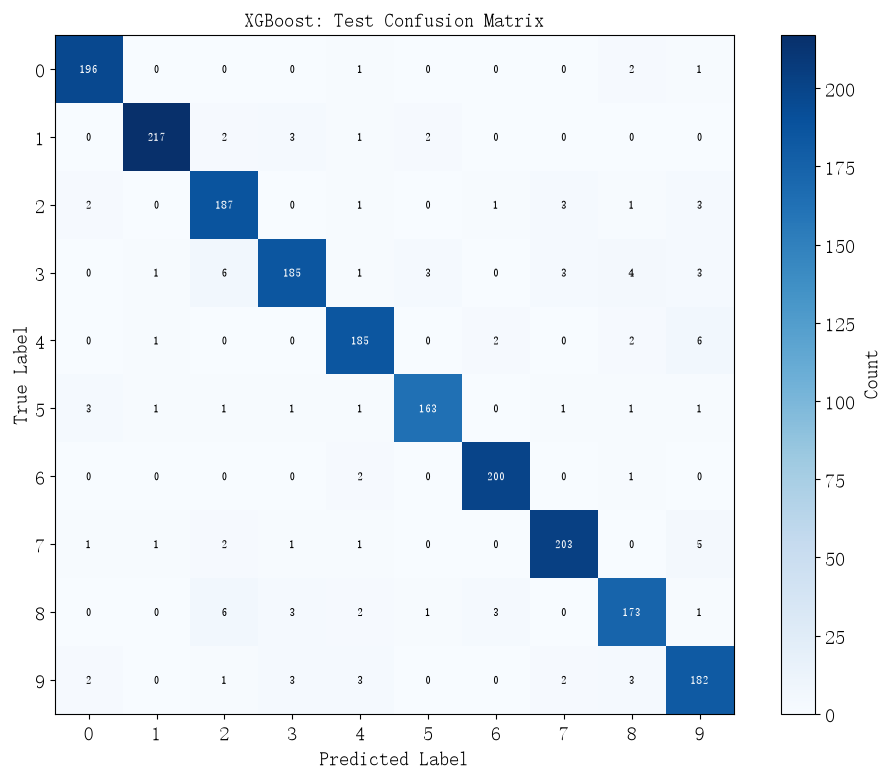

In [59]:
cm = confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
fig.colorbar(im, ax=ax, label="Count")

ax.set(
    xticks=np.arange(10),
    yticks=np.arange(10),
    xlabel="Predicted Label",
    ylabel="True Label",
    title="XGBoost: Test Confusion Matrix"
)

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, f"{cm[i, j]}",
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
            fontsize=8
        )

fig.tight_layout()
display_inline(fig)

经过正交实验和局部参数扫描，最终得到的模型参数为

$$
\begin{aligned}
n_{\mathrm{estimators}}&=180\\
\mathrm{learning\_rate}&=0.1\\
\mathrm{max\_depth}&=3\\
\mathrm{min\_child\_weight}&=0.25\\
\mathrm{subsample}&=0.8\\
\mathrm{colsample\_bytree}&=0.5\\
\mathrm{reg\_lambda}&=0.01
\end{aligned}
$$

使用完整 Train 重新训练后，模型的 Train Accuracy 为 0.997875，Test Accuracy 为 0.945500.

可以发现，模型在训练集上几乎完全拟合，但 Test Accuracy 仍低于 Train Accuracy，存在一定的泛化误差. 从混淆矩阵来看，正确分类的样本主要集中在对角线上，说明模型能够较好地识别不同的手写数字.

## 模型对比

三种模型均使用相同的 Train/Test 划分，并在训练集内部通过交叉验证进行超参数优化.

为了比较不同模型的分类效果，我们计算 Train Accuracy 和 Test Accuracy，并引入泛化差距

$$
\Delta_{\mathrm{Acc}}=\mathrm{Acc}_{\mathrm{Train}}-\mathrm{Acc}_{\mathrm{Test}}
$$

其中，Test Accuracy 反映模型对未见样本的分类能力，而泛化差距可以辅助判断模型的过拟合程度.

In [60]:
model_comparison = pd.DataFrame({
    "Train Accuracy": [
        softmax_pipeline.score(X_train, y_train),
        svm_pipeline.score(X_train, y_train),
        final_xgb.score(X_train, y_train)
    ],
    "Test Accuracy": [
        softmax_pipeline.score(X_test, y_test),
        svm_pipeline.score(X_test, y_test),
        final_xgb.score(X_test, y_test)
    ]
}, index=["Softmax Regression", "RBF-SVM", "XGBoost"])

model_comparison["Generalization Gap"] = (
    model_comparison["Train Accuracy"] - model_comparison["Test Accuracy"]
)

display(model_comparison.round(6))

,Train Accuracy,Test Accuracy,Generalization Gap
Softmax Regression,0.930625,0.9150,0.015625
RBF-SVM,0.999250,0.9685,0.030750
XGBoost,0.997875,0.9455,0.052375


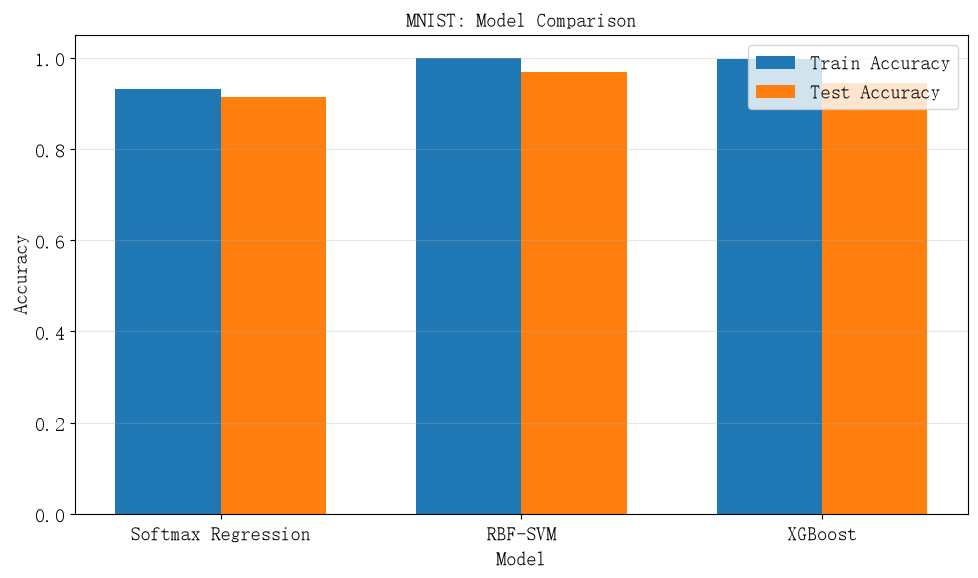

In [61]:
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(model_comparison))
width = 0.35
ax.bar(x - width / 2, model_comparison["Train Accuracy"],
       width, label="Train Accuracy")
ax.bar(x + width / 2, model_comparison["Test Accuracy"],
       width, label="Test Accuracy")
ax.set(
    xticks=x,
    xticklabels=model_comparison.index,
    xlabel="Model",
    ylabel="Accuracy",
    title="MNIST: Model Comparison"
)
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
ax.legend()
display_inline(fig)

从实验结果可以发现，三种模型的性能存在明显差异.

Softmax Regression 的 Test Accuracy 为 91.50%，低于另外两种模型. 这是因为 Softmax Regression 使用线性判别函数，难以充分描述手写数字在高维像素空间中的复杂非线性关系. 但其 Train Accuracy 与 Test Accuracy 比较接近，说明模型没有出现明显的过拟合.

RBF-SVM 的 Test Accuracy 为 96.85%，是三种模型中最高的. 相比 Softmax Regression，提高了 5%. 这说明引入 RBF 核函数后，模型能够构造更加复杂的非线性分类边界，从而更好地识别不同的数字.

XGBoost 的 Test Accuracy 为 94.55%，高于 Softmax Regression，但低于 RBF-SVM. 其 Train Accuracy 达到 99.79%，但 Train 和 Test 之间的差距也最大，说明模型具有较强的拟合能力，但在当前参数和数据集条件下，可能已经陷入了过拟合. 同时其计算是三个中最慢的，超参也是最多的，可能超参扫描和优化做的没有 RBF-SVM 好.

总体而言，本次实验中三种模型的 Test Accuracy 满足

$$
\mathrm{Acc}_{\mathrm{SVM}}>\mathrm{Acc}_{\mathrm{XGBoost}}>\mathrm{Acc}_{\mathrm{Softmax}}
$$

## 结论

本次实验使用 Softmax Regression、RBF-SVM 和 XGBoost 三种算法完成 MNIST 手写数字分类任务，并对不同模型的分类性能、参数敏感性和泛化能力进行了比较. 主要结论如下：

- Softmax Regression
  - 模型的主要限制在于其决策函数是线性的，难以充分描述高维图像特征之间复杂的非线性关系.
  - 正则化参数 `C` 控制模型的正则化强度. `C` 越大，正则化越弱，模型可以更加充分地拟合训练数据. 但减弱正则化并不能解决线性模型本身的表达能力限制.
  - `max_iter` 和 `tol` 主要影响优化过程的迭代次数和收敛条件，本次实验中由于模型本身表达能力的限制，这两个参数更多影响训练时间
  - Test Acc：91.50%.

- RBF-SVM
  - 本次采用 RBF 核函数，其主要参数为 `C` 和 `gamma`. 其中，`C` 控制分类间隔与训练误差之间的权衡，`gamma` 控制核函数的空间尺度，两者共同决定分类边界的复杂程度.
  - 两个参数存在相互影响，因此采用联合扫描.
  - 相比线性 Softmax Regression，RBF-SVM 能够构造更加灵活的非线性分类边界，因此在复杂图像分类任务中具有更强的表达能力.
  - Test Acc：96.85%.

- XGBoost
  - 训练轮数 `n_estimators` 和学习率 `learning_rate` 共同决定 Boosting 过程的迭代规模与每轮更新幅度.
  - 正交实验表明，在当前考察范围内，`min_child_weight` 是影响模型性能最显著的参数. 它控制树的分裂条件和模型复杂度. `subsample` 和 `colsample_bytree` 分别控制样本采样比例和特征采样比例，在我们的正交实验中也是影响较大的超参.
  - 相比之下，`max_depth` 和 `reg_lambda` 在当前实验范围内对模型准确率影响较小. 其中，`reg_lambda` 是叶节点权重的 L2 正则化系数，用于抑制模型复杂度. 参数敏感性与所选择的取值范围有关. 在我们的实验范围内，其对模型准确率影响较小.
  - 最终采用正交实验筛选与局部联合扫描相结合的方式，减少了直接进行高维全参数搜索的计算开销.
  - Test Acc：94.55%.

- 综合比较与分析

  - 三种模型的 Test Accuracy 排序为：
    $$
    \mathrm{RBF\text{-}SVM}>\mathrm{XGBoost}>\mathrm{Softmax\ Regression}
    $$

  - Softmax Regression 结构简单、训练过程直接，但受到线性决策边界的限制，在复杂的图像分类任务中表达能力不足.
  - RBF-SVM 利用核函数引入非线性映射，在分类间隔与模型复杂度之间取得了较好的平衡，因此取得了最好的测试表现.
  - XGBoost 通过集成多棵决策树构造非线性分类模型，具有较强的特征划分和拟合能力，但模型训练较慢，涉及多个超参，超参调整比较麻烦，可能在我们的实验范围内超参调整不够好，导致 Train Acc 和 Test Acc 差距较大（呈现过拟合）.

## 参考资料及 AI 使用说明

- 背景补充部分个人写出大体大纲，使用 GPT 6 Astra 生成并进行人工核验和修改.
- 代码编写使用 Deepseek V4 Flash FIM 模式进行补全和生成（尤其是绘图相关函数，基本是直接生成），经过人工核验和运行验证.
- 扫参函数由 GPT 6 生成，经过人工核验和运行验证.
- 文本和公式编写使用 Deepseek V4 Flash FIM 模式进行生成和补全，经过人工核验和修改.
- 结果描述使用 GPT 6 给出，经过人工核验和修改.

## 致谢

暂无.

## 附一：问题

- 实验中我们可以注意到，在大数据量大特征量的情况下，SVM 和 XGBoost 训练较慢，每一次训练都需要使用全部数据进行训练，训练速度被内存带宽等限制，计算过程也难以并行化（一般只能不同超参的并行化扫描），从而使得难以 Scaling Up（从这个角度看神经网络等适合 Scaling Up，因此目前 AI 大部分使用神经网络，更适合超大规模的数据训练）. 那么，对于 Softmax Regression、SVM、XGBoost，是否有使用 GPU 并行计算的方法？是否也可以类似神经网络使用 Mini Batch 进行训练，从而便于在更大规模的数据进行训练？
- 目前我们使用“正交实验”的方法确认主要影响参数，再主要优化主要影响超参的值. 但如果两个参数存在强烈的交互作用，正交实验得到的敏感性排序不一定仍旧可靠. 同时正交实验依赖于合适的参数范围选取，有可能某个参数的影响较小，是因为它本身不重要，也可能是所选择的水平范围不合理，
- 由于 XGBoost 超参较多，同时计算效率较慢，因此，我们基本没有绘制模型 Acc 随着某一个超参的变化图，也没有绘制多个超参的精度较高的热力图，这是本次实验的一个问题和限制
- 如何在有限的计算预算下，兼顾参数搜索范围、搜索精度和交叉验证次数？有什么更好的方法可以进行更好的搜索？

## 附二：学习心得

暂无